In [110]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sqlalchemy import create_engine

pd.set_option("display.float_format", "{:.2f}".format)

engine = create_engine(
    "postgresql+psycopg://aikalee@localhost:5432/healthcare"
)

In [114]:
pd.read_sql("SELECT * FROM wait_times_clean LIMIT 5", engine)

,ref_date,geo,gender,age_group,indicators,number_high_95,percentage_high_95,number_low_95,percentage_low_95,number,percentage,different_from_canada_rate
0,2024,Alberta,Both genders,18 to 44 years,Life affected by wait time,408400.00,71.40,319500.00,60.90,363700.00,66.30,0.00
1,2024,Alberta,Both genders,18 to 44 years,Satisfaction with wait time - Dissatisfied or very dissatisfied,242200.00,43.00,173900.00,32.50,206800.00,37.60,0.00
2,2024,Alberta,Both genders,18 to 44 years,Satisfaction with wait time - Very satisfied or satisfied,258500.00,46.10,186600.00,35.10,222600.00,40.50,0.00
3,2024,Alberta,Both genders,18 to 44 years,"Total, wait time - medical specialist",594600.00,100.00,493100.00,100.00,546900.00,100.00,NaN
4,2024,Alberta,Both genders,18 to 44 years,"Wait time, 3 months to less than 6 months",112500.00,20.80,66400.00,12.80,89800.00,16.40,0.00


In [18]:
pd.read_sql_query("SELECT DISTINCT indicators FROM wait_times_clean", engine)

,indicators
0,"Wait time, 6 months or more"
1,"Wait time, 3 months to less than 6 months"
2,Satisfaction with wait time - Very satisfied or satisfied
3,"Wait time, less than 3 months"
4,Life affected by wait time
5,"Total, wait time - medical specialist"
6,Satisfaction with wait time - Dissatisfied or very dissatisfied


In [25]:
pd.read_sql_query("SELECT DISTINCT age_group FROM wait_times_clean", engine)

,age_group
0,65 years and over
1,45 to 64 years
2,"Total, 18 years and over"
3,18 to 44 years


In [26]:
pd.read_sql_query("SELECT DISTINCT gender FROM wait_times_clean", engine)

,gender
0,Women+
1,Both genders
2,Men+


### 1. How does access to healthcare in British Columbia compare with other Canadian provinces?

#### 1.0 Total waited population validation

In [121]:
q1_0 = pd.read_sql(
    """
    WITH life_affected AS (
        SELECT
            geo,
            SUM(number) AS affected_number,
            SUM(number / (percentage / 100.0)) AS inferred_denominator
        FROM wait_times_clean
        WHERE indicators = 'Life affected by wait time'
          AND gender = 'Both genders'
          AND percentage > 0
        GROUP BY geo
    ),
    total_wait AS (
        SELECT
            geo,
            SUM(number) AS total_wait_population
        FROM wait_times_clean
        WHERE indicators = 'Total, wait time - medical specialist'
          AND gender = 'Both genders'
        GROUP BY geo
    )
    
    SELECT
        l.geo,
        l.inferred_denominator,
        t.total_wait_population,
        ABS(l.inferred_denominator - t.total_wait_population) AS difference,
        ABS(l.inferred_denominator - t.total_wait_population)
            / t.total_wait_population * 100 AS relative_error
    FROM life_affected l
    JOIN total_wait t
        ON l.geo = t.geo
    ORDER BY relative_error DESC;
    """,
    engine
)

q1_0

,geo,inferred_denominator,total_wait_population,difference,relative_error
0,Quebec,4708517.35,4693800.00,14717.35,0.31
1,Newfoundland and Labrador,278051.52,277200.00,851.52,0.31
2,Nova Scotia,474433.00,473000.00,1433.00,0.30
3,New Brunswick,385913.48,387000.00,1086.52,0.28
4,Saskatchewan,502195.52,503300.00,1104.48,0.22
5,Alberta,2478526.88,2473200.00,5326.88,0.22
6,Prince Edward Island,71519.21,71400.00,119.21,0.17
7,Manitoba,647333.00,648400.00,1067.00,0.16
8,Ontario,9156056.14,9167400.00,11343.86,0.12
9,British Columbia,2854455.72,2851000.00,3455.72,0.12


The inferred denominators differed from the reported total wait-time population by only 0.07%–0.31% across all geographies, supporting the use of the total specialist wait-time population as the denominator for calculating the overall rate.

#### 1.1 Population waited over 6 months

In [122]:
q1_1 = pd.read_sql(
    """
    WITH wait_6_months AS (
        SELECT
            geo,
            SUM(number) AS wait_6m
        FROM wait_times_clean
        WHERE indicators = 'Wait time, 6 months or more'
        AND gender = 'Both genders'
        GROUP BY geo
    ),
    total_wait AS (
        SELECT
            geo,
            SUM(number) AS total_wait
        FROM wait_times_clean
        WHERE indicators = 'Total, wait time - medical specialist'
        AND gender = 'Both genders'
        GROUP BY geo
    )

    SELECT
        w.geo,
        w.wait_6m,
        t.total_wait,
        w.wait_6m / t.total_wait * 100 AS overall_percentage
    FROM wait_6_months w
    JOIN total_wait t
        ON w.geo = t.geo
    ORDER BY overall_percentage;
    """,
    engine
)
q1_1

,geo,wait_6m,total_wait,overall_percentage
0,Ontario,1501600.00,9167400.00,16.38
1,Canada (excluding territories),3926000.00,21545700.00,18.22
2,British Columbia,535700.00,2851000.00,18.79
3,Saskatchewan,95100.00,503300.00,18.90
4,Quebec,897400.00,4693800.00,19.12
5,Alberta,488800.00,2473200.00,19.76
6,Manitoba,132500.00,648400.00,20.43
7,New Brunswick,80400.00,387000.00,20.78
8,Nova Scotia,110000.00,473000.00,23.26
9,Newfoundland and Labrador,66000.00,277200.00,23.81


In [123]:
provincial_median = q1_1["overall_percentage"].median()

bc_percentage = q1_1.loc[
    q1_1["geo"] == "British Columbia",
    "overall_percentage"
].iloc[0]

difference = bc_percentage - provincial_median

print(f"BC: {bc_percentage:.2f}%")
print(f"Provincial median: {provincial_median:.2f}%")
print(f"Difference: {difference:.2f} percentage points")

BC: 18.79%
Provincial median: 19.76%
Difference: -0.97 percentage points


BC 18.81% is lower than the provincial median of 20.10%, indicating relatively favourable performance compared with a typical province. However, it is slightly higher than the Canada-wide estimate of 18.22%.

#### 1.2 Life affected population

In [124]:
q1_2 = pd.read_sql(
    """
    WITH life_affected_by_wait_time AS (
            SELECT
                geo,
                SUM(number) AS life_affected
            FROM wait_times_clean
            WHERE indicators = 'Life affected by wait time'
            AND gender = 'Both genders'
            GROUP BY geo
    ),
    total_wait AS (
        SELECT
            geo,
            SUM(number) AS total_wait
        FROM wait_times_clean
        WHERE indicators = 'Total, wait time - medical specialist'
        AND gender = 'Both genders'
        GROUP BY geo
        )
    
    SELECT
        w.geo,
        w.life_affected,
        t.total_wait,
        w.life_affected / t.total_wait * 100 AS overall_percentage
    FROM  life_affected_by_wait_time w
    JOIN total_wait t
        ON w.geo = t.geo
    WHERE w.geo <> 'Canada (excluding territories)'
    ORDER BY overall_percentage;
    """,
    engine
)
q1_2

,geo,life_affected,total_wait,overall_percentage
0,New Brunswick,210300.00,387000.00,54.34
1,Quebec,2793300.00,4693800.00,59.51
2,Newfoundland and Labrador,172100.00,277200.00,62.09
3,Manitoba,411100.00,648400.00,63.40
4,Ontario,5850800.00,9167400.00,63.82
5,Prince Edward Island,46700.00,71400.00,65.41
6,Nova Scotia,312700.00,473000.00,66.11
7,Alberta,1640200.00,2473200.00,66.32
8,British Columbia,1929600.00,2851000.00,67.68
9,Saskatchewan,349000.00,503300.00,69.34


In [125]:
provincial_median = q1_2["overall_percentage"].median()

bc_percentage = q1_2.loc[
    q1_2["geo"] == "British Columbia",
    "overall_percentage"
].iloc[0]

difference = bc_percentage - provincial_median

print(f"BC: {bc_percentage:.2f}%")
print(f"Provincial median: {provincial_median:.2f}%")
print(f"Difference: {difference:.2f} percentage points")


BC: 67.68%
Provincial median: 64.61%
Difference: 3.07 percentage points


British Columbia had the second-highest proportion of patients reporting that their lives were affected by specialist wait times (67.68%), despite having a relatively low rate of waits lasting six months or more.

#### 1.3 Dissatisfied Population

In [126]:
q1_3 = pd.read_sql(
    """
    WITH dissatisfied_with_wait_time AS (
            SELECT
                geo,
                SUM(number) AS dissatisfied
            FROM wait_times_clean
            WHERE indicators = 'Satisfaction with wait time - Dissatisfied or very dissatisfied'
            AND gender = 'Both genders'
            GROUP BY geo
    ),
    total_wait AS (
        SELECT
            geo,
            SUM(number) AS total_wait
        FROM wait_times_clean
        WHERE indicators = 'Total, wait time - medical specialist'
        AND gender = 'Both genders'
        GROUP BY geo
        )
    
    SELECT
        w.geo,
        w.dissatisfied,
        t.total_wait,
        w.dissatisfied / t.total_wait * 100 AS overall_percentage
    FROM  dissatisfied_with_wait_time w
    JOIN total_wait t
        ON w.geo = t.geo
    WHERE w.geo <> 'Canada (excluding territories)'
    ORDER BY overall_percentage;
    """,
    engine
)
q1_3

,geo,dissatisfied,total_wait,overall_percentage
0,Quebec,1079700.00,4693800.00,23.00
1,New Brunswick,99100.00,387000.00,25.61
2,Newfoundland and Labrador,79400.00,277200.00,28.64
3,Prince Edward Island,21000.00,71400.00,29.41
4,Nova Scotia,142100.00,473000.00,30.04
5,Manitoba,198000.00,648400.00,30.54
6,Saskatchewan,156000.00,503300.00,31.00
7,British Columbia,951400.00,2851000.00,33.37
8,Alberta,830100.00,2473200.00,33.56
9,Ontario,3129000.00,9167400.00,34.13


In [127]:
provincial_median = q1_3["overall_percentage"].median()

bc_percentage = q1_3.loc[
    q1_3["geo"] == "British Columbia",
    "overall_percentage"
].iloc[0]

difference = bc_percentage - provincial_median

print(f"BC: {bc_percentage:.2f}%")
print(f"Provincial median: {provincial_median:.2f}%")
print(f"Difference: {difference:.2f} percentage points")


BC: 33.37%
Provincial median: 30.29%
Difference: 3.08 percentage points


British Columbia had the third-highest dissatisfaction rate with specialist wait times among the provinces, at 33.37%, behind only Ontario and Alberta.

#### 1.4 Short summary

Although British Columbia performed relatively well on prolonged specialist wait times, ranking second-lowest in the proportion waiting six months or more, patient-reported outcomes were less favourable: BC had the second-highest rate of reported life impact and the third-highest rate of dissatisfaction with wait times.

### 2. How are prolonged specialist wait times, reported life impact, and patient dissatisfaction related across Canadian provinces?

In [99]:
q2 = pd.read_sql(
    """
    WITH total_wait AS (
        SELECT
            geo,
            SUM(number) AS total_wait
        FROM wait_times_clean
        WHERE indicators = 'Total, wait time - medical specialist'
          AND gender = 'Both genders'
        GROUP BY geo
    ),

    wait_6m AS (
        SELECT
            geo,
            SUM(number) AS wait_6m
        FROM wait_times_clean
        WHERE indicators = 'Wait time, 6 months or more'
          AND gender = 'Both genders'
        GROUP BY geo
    ),

    life_affected AS (
        SELECT
            geo,
            SUM(number) AS life_affected
        FROM wait_times_clean
        WHERE indicators = 'Life affected by wait time'
          AND gender = 'Both genders'
        GROUP BY geo
    ),

    dissatisfied AS (
        SELECT
            geo,
            SUM(number) AS dissatisfied
        FROM wait_times_clean
        WHERE indicators =
            'Satisfaction with wait time - Dissatisfied or very dissatisfied'
          AND gender = 'Both genders'
        GROUP BY geo
    )

    SELECT
        t.geo,
        w.wait_6m / t.total_wait * 100 AS wait_6m_pct,
        l.life_affected / t.total_wait * 100 AS life_affected_pct,
        d.dissatisfied / t.total_wait * 100 AS dissatisfied_pct
    FROM total_wait t
    JOIN wait_6m w ON t.geo = w.geo
    JOIN life_affected l ON t.geo = l.geo
    JOIN dissatisfied d ON t.geo = d.geo
    WHERE t.geo <> 'Canada (excluding territories)'
    ORDER BY t.geo;
    """,
    engine
)

q2

,geo,wait_6m_pct,life_affected_pct,dissatisfied_pct
0,Alberta,19.76,66.32,33.56
1,British Columbia,18.79,67.68,33.37
2,Manitoba,20.43,63.40,30.54
3,New Brunswick,20.78,54.34,25.61
4,Newfoundland and Labrador,23.81,62.09,28.64
5,Nova Scotia,23.26,66.11,30.04
6,Ontario,16.38,63.82,34.13
7,Prince Edward Island,25.63,65.41,29.41
8,Quebec,19.12,59.51,23.00
9,Saskatchewan,18.90,69.34,31.00


In [100]:
q2[
    ["wait_6m_pct", "life_affected_pct", "dissatisfied_pct"]
].corr(method="pearson")

,wait_6m_pct,life_affected_pct,dissatisfied_pct
wait_6m_pct,1.00,-0.05,-0.29
life_affected_pct,-0.05,1.00,0.72
dissatisfied_pct,-0.29,0.72,1.00


In [102]:
corr_life = q2["wait_6m_pct"].corr(q2["life_affected_pct"])
corr_dissatisfied = q2["wait_6m_pct"].corr(q2["dissatisfied_pct"])
corr_life_dissatisfied = q2["life_affected_pct"].corr(q2["dissatisfied_pct"])

print(f"6+ month wait vs life affected: {corr_life:.2f}")
print(f"6+ month wait vs dissatisfaction: {corr_dissatisfied:.2f}")
print(f"Life affected vs dissatisfaction: {corr_life_dissatisfied:.2f}")

6+ month wait vs life affected: -0.05
6+ month wait vs dissatisfaction: -0.29
Life affected vs dissatisfaction: 0.72


### 3. Visualizations

Matplotlib is building the font cache; this may take a moment.


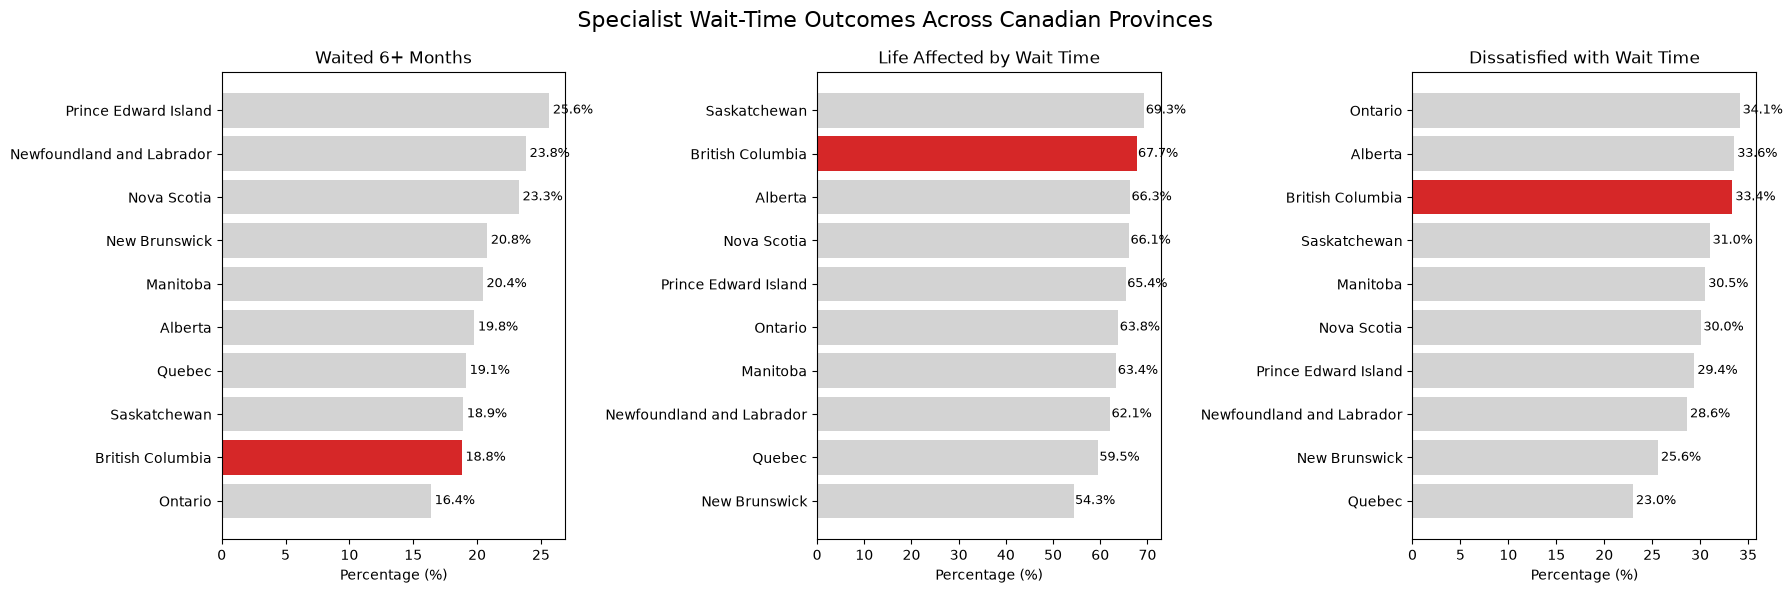

In [ ]:
indicators = {
    "wait_6m_pct": "Waited 6+ Months",
    "life_affected_pct": "Life Affected by Wait Time",
    "dissatisfied_pct": "Dissatisfied with Wait Time"
}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (column, title) in zip(axes, indicators.items()):
    
    plot_q1 = q2.sort_values(column, ascending=True)
    
    colors = [
        "tab:red" if geo == "British Columbia" else "lightgray"
        for geo in plot_q1["geo"]
    ]
    
    ax.barh(
        plot_q1["geo"],
        plot_q1[column],
        color=colors
    )
    
    ax.set_title(title)
    ax.set_xlabel("Percentage (%)")
    
    # Add percentage labels
    for i, value in enumerate(plot_q1[column]):
        ax.text(
            value + 0.3,
            i,
            f"{value:.1f}%",
            va="center",
            fontsize=9
        )

fig.suptitle(
    "Specialist Wait-Time Outcomes Across Canadian Provinces",
    fontsize=16
)

plt.tight_layout()
plt.show()

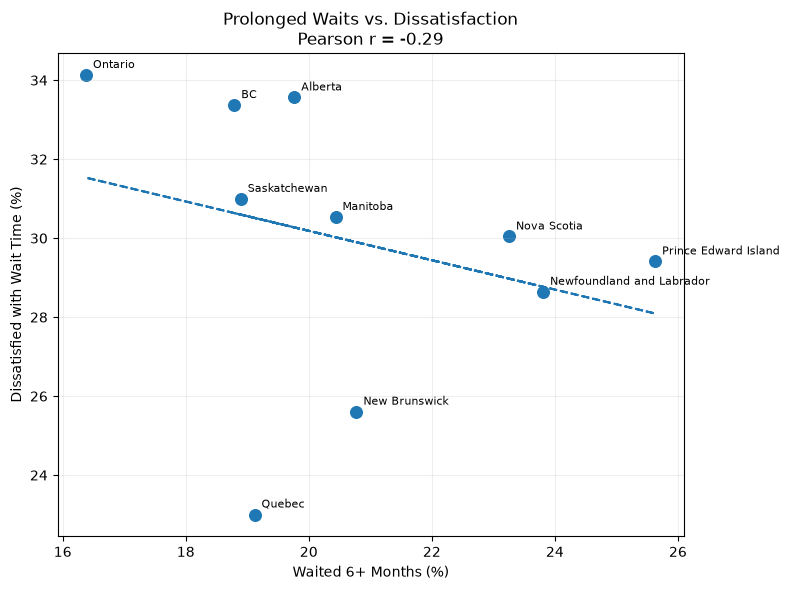

In [108]:
x = q2["wait_6m_pct"]
y = q2["dissatisfied_pct"]

plt.figure(figsize=(8, 6))

plt.scatter(x, y, s=70)

m, b = np.polyfit(x, y, 1)
plt.plot(x, m * x + b, linestyle="--")

for _, row in q2.iterrows():
    label = (
        "BC"
        if row["geo"] == "British Columbia"
        else row["geo"]
    )
    
    plt.annotate(
        label,
        (row["wait_6m_pct"], row["dissatisfied_pct"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Waited 6+ Months (%)")
plt.ylabel("Dissatisfied with Wait Time (%)")
plt.title(
    "Prolonged Waits vs. Dissatisfaction\n"
    f"Pearson r = {corr_dissatisfied:.2f}"
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

The prevalence of waits lasting six months or more showed only a weak relationship with dissatisfaction across provinces (r = −0.29), suggesting that the six-month threshold alone does not adequately represent patient experience.

### 4.Summary

British Columbia showed comparatively favourable performance on prolonged specialist waits, with the second-lowest proportion of patients waiting six months or more. However, patient-reported outcomes were less favourable: BC ranked second-highest in reported life impact and third-highest in dissatisfaction. Across provinces, prolonged waits were weakly related to dissatisfaction (r = −0.29) and essentially unrelated to reported life impact (r = −0.05), while life impact and dissatisfaction were strongly positively correlated (r = 0.72). These findings suggest that the prevalence of six-month-or-longer waits alone may not adequately capture patients’ experience of specialist care.